
$\hat{y}_1=f_1(X)$

$\hat{x}=f_2(X,\hat{y}_1)$

$\hat{y}=f_3(X,\hat{y}_1,\hat{x})$

$\hat{r}=f_4(X,\hat{y}_1,\hat{x},\hat{y})$

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_squared_error, r2_score, mean_absolute_error, adjusted_rand_score
from sklearn.model_selection import KFold, cross_val_predict
from xgboost import XGBRegressor

from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('databasev4_2.csv')

print(df['presence'].value_counts())

display(df.columns)

# na = ["a_rel_10mm","a_rel_20mm","a_rel_30mm","a_rel_40mm","eco2_atraso","eco2_razao"]
# df = df.drop(columns=na)

# df = df[df['radius']>=0.01].reset_index(drop=True)

# df = df[df['soil_type']==1].reset_index(drop=True)

# cp = pd.read_csv('databasev5_presenca.csv')

# df = df[cp['classe']==2]
# df = df[(df['pos_x']>0.08) & (df['pos_x']<0.2)].reset_index(drop=True)
# df = df[df['presence']==1]
# na = ["a_rel_10mm","a_rel_20mm","a_rel_30mm","a_rel_40mm","eco2_atraso","eco2_razao"]
# df = df.drop(columns=na)

# EXTRAIR FEATURES NOVAS COM CODIGO DO CLAUDE

# PCA???

# Tá desbalanceado??

presence
1    3782
0    1218
Name: count, dtype: int64


Index(['soil_type', 'presence', 'pos_x', 'pos_y', 'radius', 'x_pico_env',
       't_pico_env', 'x0_fit', 't0_fit', 'v_fit', 'd_apex', 'score_fit',
       'score_contraste', 'flag_borda_x', 'flag_borda_t', 'a_max', 'larg_x_50',
       'larg_x_25', 'a_rel_10mm', 'a_rel_20mm', 'a_rel_30mm', 'a_rel_40mm',
       'frac_energia_banda', 'rms_banda', 'clutter_rms', 'clutter_env_med',
       'snr_env', 'snr_rms', 'larg_t_50', 'larg_t_25', 'eco2_atraso',
       'eco2_razao', 'freq_centroid_apex', 'freq_peak_apex', 'freq_bw_apex',
       'freq_centroid_global', 'freq_centroid_razao', 'freq_bw_razao',
       'rms_global', 'kurtosis_global', 'q99_env', 'apex_sobre_rms', 'bg_rms',
       'bg_t_pico'],
      dtype='object')

In [3]:
def print_results(reg:bool,y_test,y_pred):
    if reg == True:
        print('R²:', r2_score(y_test, y_pred))
        print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
        print('MAE:', mean_absolute_error(y_test, y_pred))
    else:
        print("Acurácia:", accuracy_score(y_test,y_pred))
        print("\nMatriz de confusão:\n",confusion_matrix(y_test,y_pred))
        print("\nRelatório:\n",classification_report(y_test,y_pred))

Models

In [4]:
cv = KFold(n_splits=10,shuffle=False)

hgb = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=100, max_leaf_nodes=31,
                                     max_depth=None, min_samples_leaf=20, l2_regularization=0.0, random_state=42 )

model_xg = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=5,
                        subsample=0.8, colsample_bytree=0.8, objective='reg:squarederror', random_state=42,n_jobs=-1)

svrm = Pipeline([('scaler', StandardScaler()),
                  ('svr', SVR(kernel='rbf', C=0.04, epsilon=0.004, gamma=0.015))])

Detecção da presença do cilindro via Gradient Boosting Classifier

In [5]:
X = df.drop(columns=['soil_type','radius','pos_x','pos_y','presence'])
Y = df['presence']

y1 = cross_val_predict(hgb, X, Y,cv=cv, method='predict')
y1 = pd.DataFrame(y1).rename(columns={0:'presence_pred'})

print_results(reg=False,y_test=Y,y_pred=y1)

Acurácia: 0.9316

Matriz de confusão:
 [[1024  194]
 [ 148 3634]]

Relatório:
               precision    recall  f1-score   support

           0       0.87      0.84      0.86      1218
           1       0.95      0.96      0.96      3782

    accuracy                           0.93      5000
   macro avg       0.91      0.90      0.91      5000
weighted avg       0.93      0.93      0.93      5000



Previsão do tipo de solo?

In [6]:
Y = df['soil_type'][y1['presence_pred']==1]

print(Y.value_counts())

soil_type
1    1383
2    1233
3    1212
Name: count, dtype: int64


Predição da posição lateral via Gradient Boosting Regressor

In [7]:
X2 = X[y1['presence_pred']==1]
Y2 = df['pos_x'][y1['presence_pred']==1]

y2 = cross_val_predict(model_xg, X2, Y2,cv=cv, method='predict')
y2 = pd.DataFrame(y2)
y2 = y2.rename(columns={0:'pos_x_pred'})

print('Posição em x:')
print_results(reg=True,y_test=Y2,y_pred=y2)

Posição em x:
R²: 0.8971550745518375
RMSE: 0.013932351724093755
MAE: 0.009303695040481003


Predição da posição vertical via XGBoost

In [8]:
X3 = pd.concat((X2.reset_index(drop=True),y2),axis=1)
Y3 = df['pos_y'][y1['presence_pred']==1].reset_index(drop=True)

y3 = cross_val_predict(model_xg, X3, Y3,cv=cv, method='predict')
y3 = pd.DataFrame(y3).rename(columns={0:'pos_y_pred'})

print_results(reg=True,y_test=Y3,y_pred=y3)

R²: 0.8360487650372378
RMSE: 0.006116450215845293
MAE: 0.004852092755801806


Predição do raio via XGBoost

In [9]:
X4 = pd.concat((X3,y3),axis=1)
# X4 =  pd.read_csv('features_raio.csv')

Y4 = df['radius'][y1['presence_pred']==1].reset_index(drop=True)
y4 = cross_val_predict(model_xg, X4, Y4,cv=cv, method='predict')
y4 = pd.DataFrame(y4)
y4 = y4.rename(columns={0:'radius_pred'})

print('Raio:')
print_results(reg=True,y_test=Y4,y_pred=y4)

# # APLICAR CNN!!!!
# # R2 AJUSTADO, VERIFICAR ROI

Raio:
R²: 0.2163984581112881
RMSE: 0.00375495806256249
MAE: 0.0031308904370002198


Predição do raio via SVRM

In [10]:
# X4 = pd.concat((X3,y3),axis=1)
# Y4 = df['radius'][y1['presence_pred']==1].reset_index(drop=True)

# y4 = cross_val_predict(svrm, X4, Y4,cv=cv, method='predict')
# y4 = pd.DataFrame(y4)
# y4 = y4.rename(columns={0:'radius_pred'})

# print('Raio:')
# print_results(reg=True,y_test=Y4,y_pred=y4)

# from sklearn.model_selection import GridSearchCV

# param_grid = {
#     'svr__C': [0.1, 1, 10, 100, 1000],
#     'svr__epsilon': [0.01, 0.1, 0.2, 0.5, 1],
#     'svr__gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
# }

# grid = GridSearchCV(
#     estimator=model,
#     param_grid=param_grid,
#     cv=5,
#     scoring='neg_mean_squared_error',
#     n_jobs=-1,
#     verbose=1
# )

# grid.fit(X_train, y_train)

# print("Melhores parâmetros:", grid.best_params_)

# best_model = grid.best_estimator_

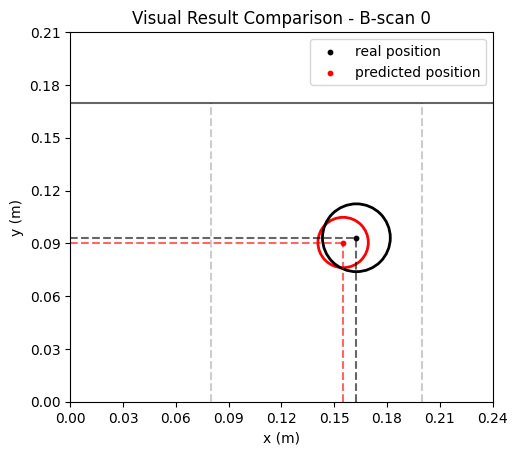

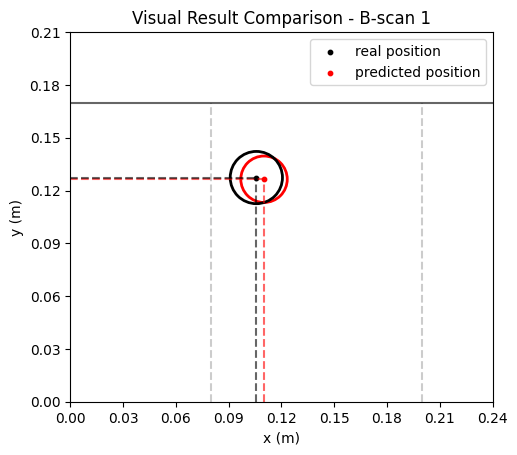

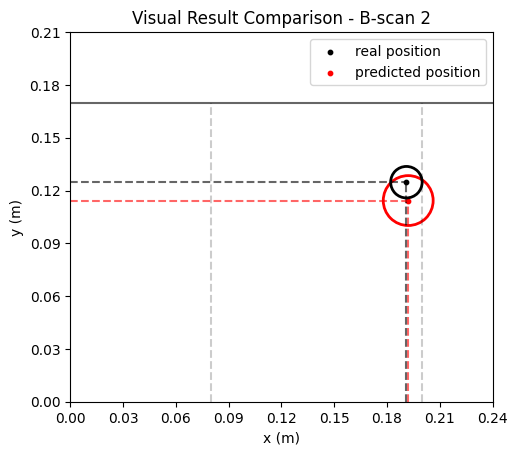

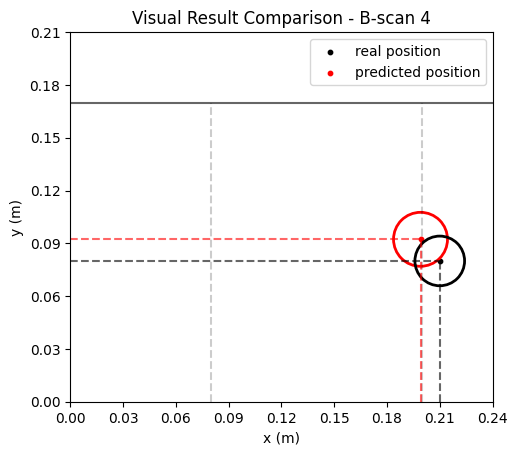

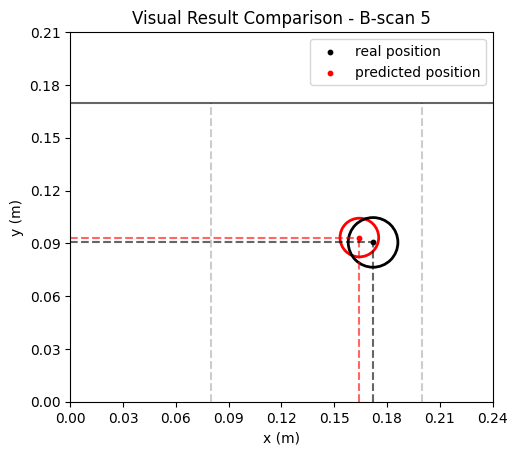

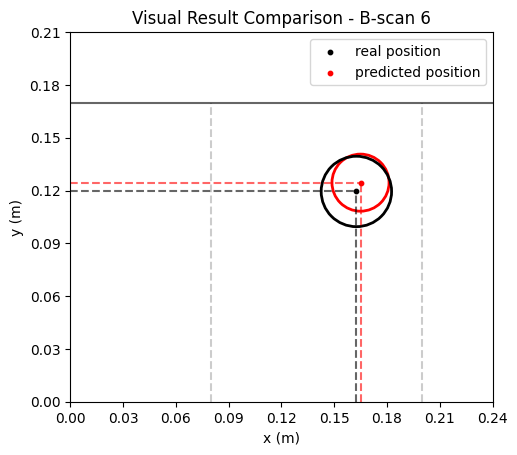

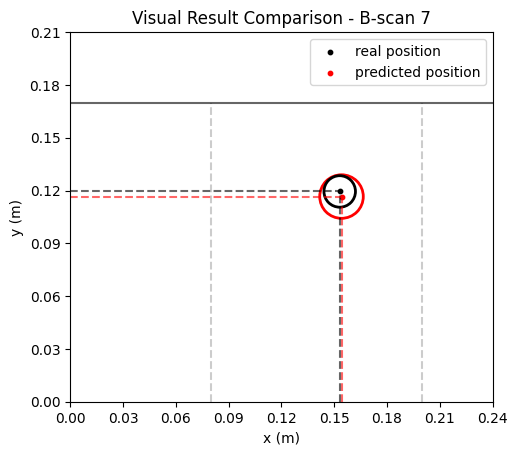

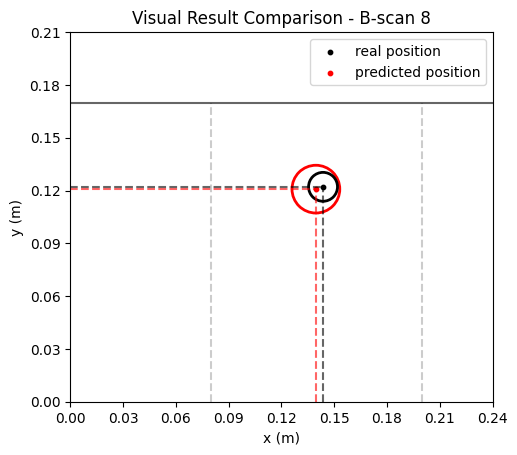

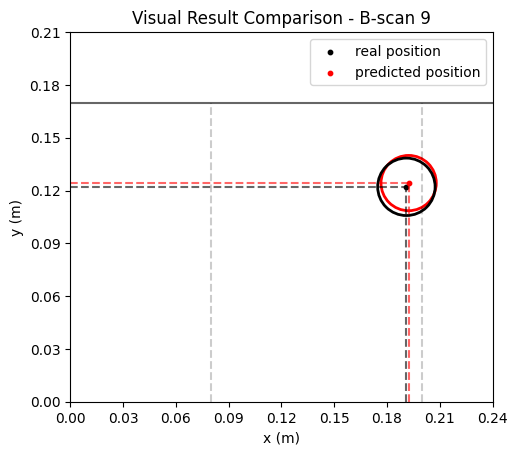

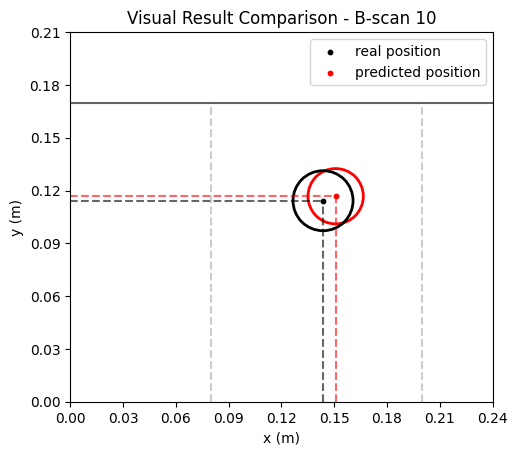

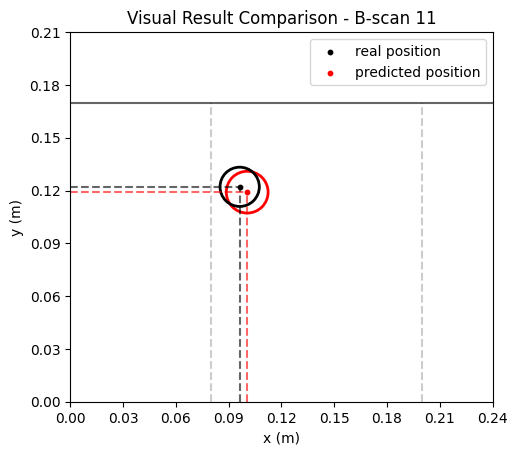

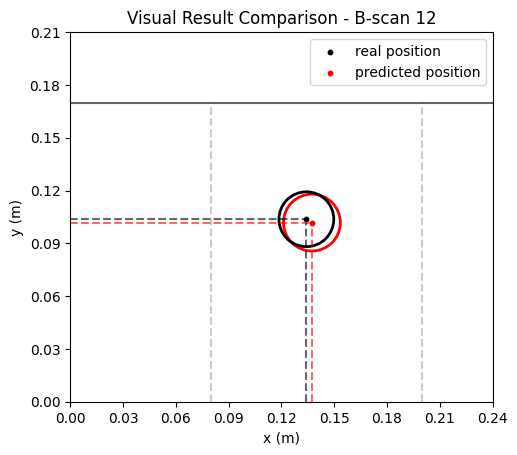

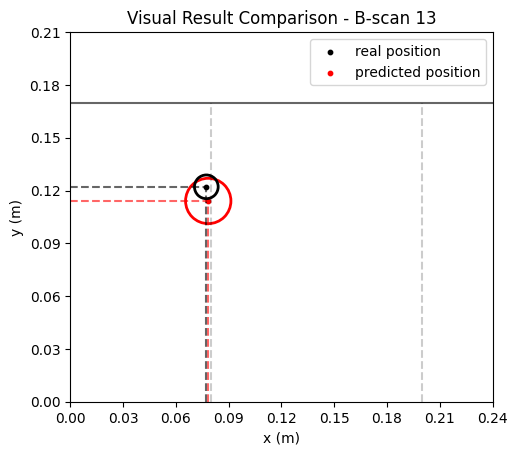

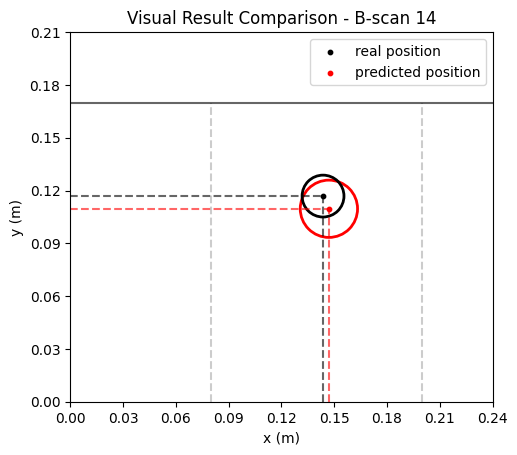

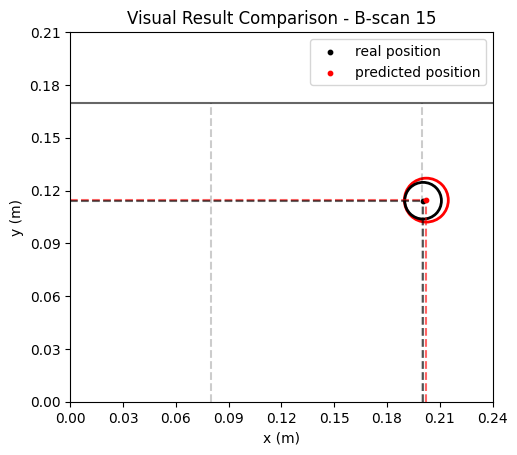

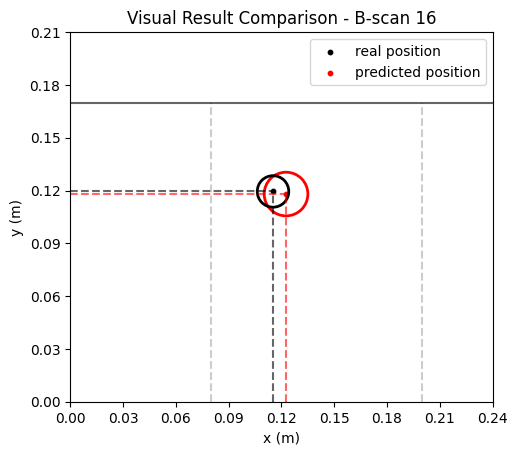

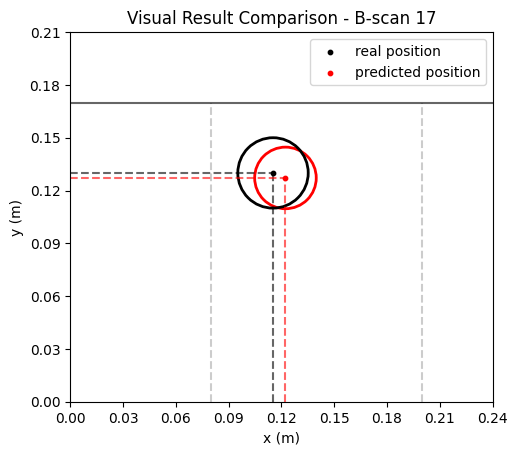

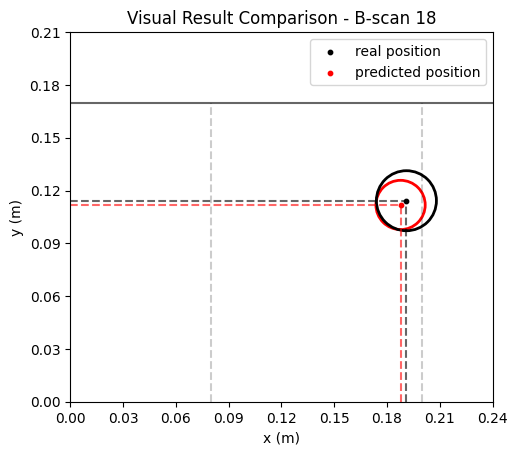

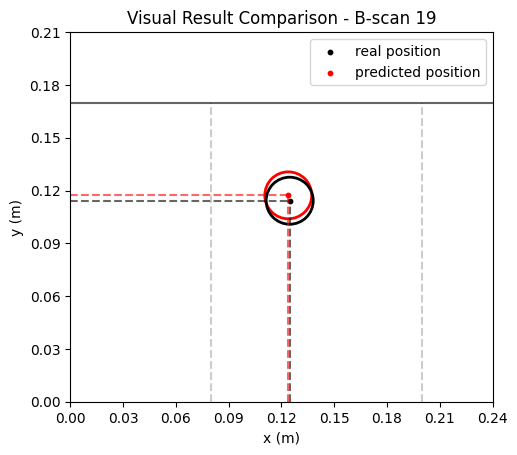

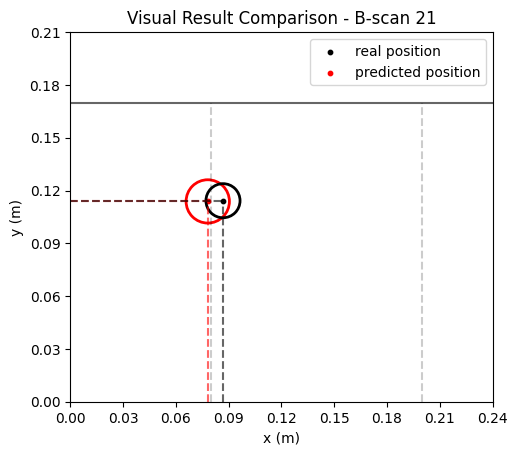

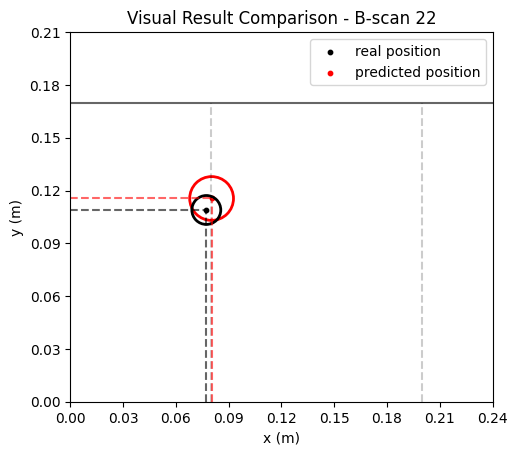

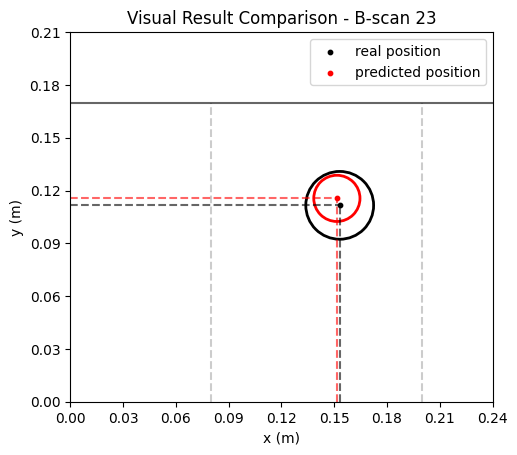

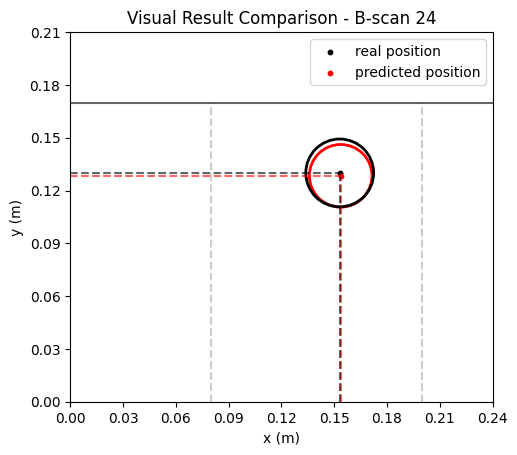

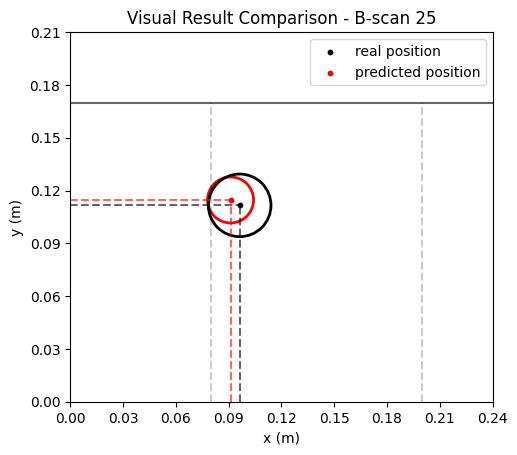

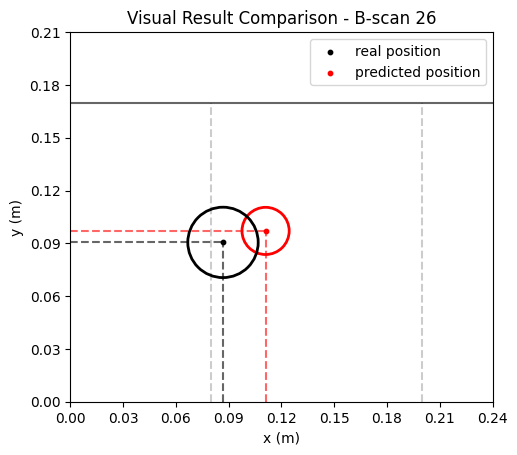

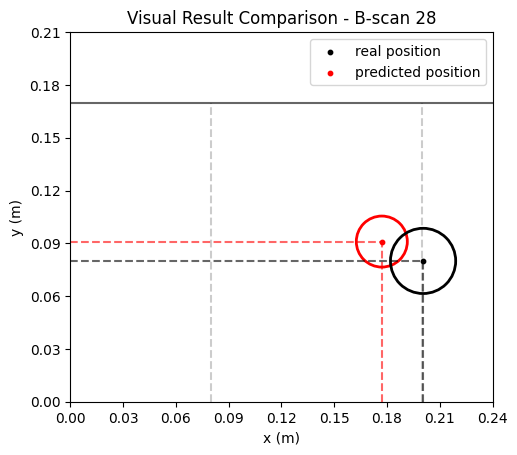

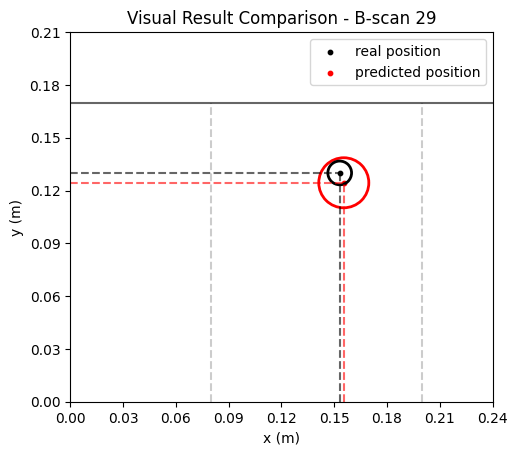

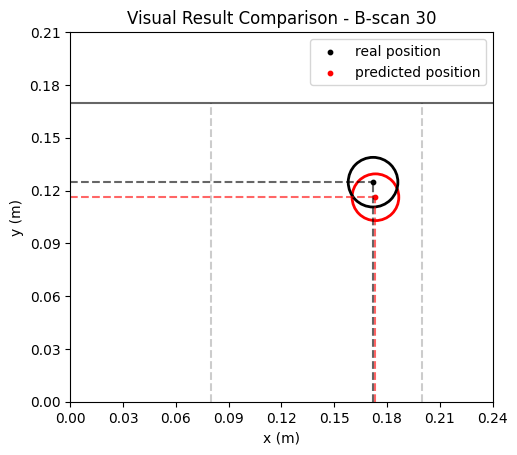

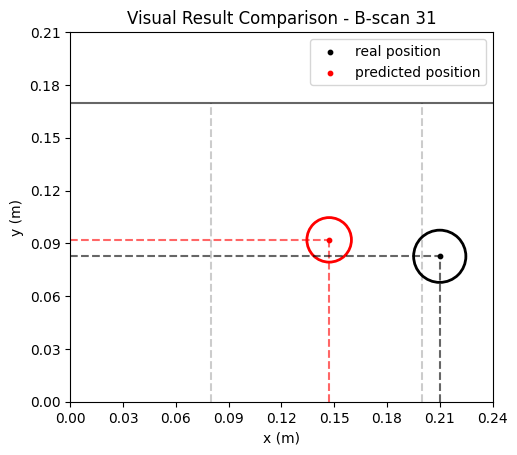

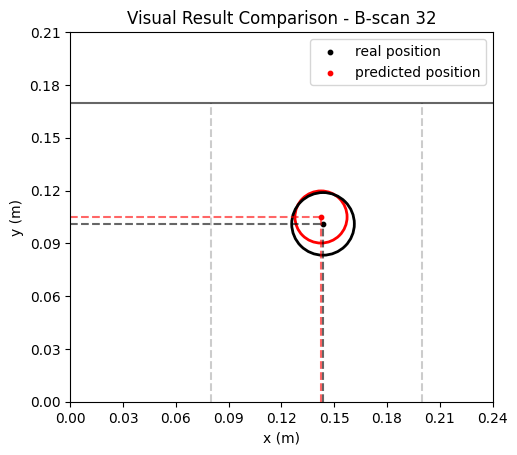

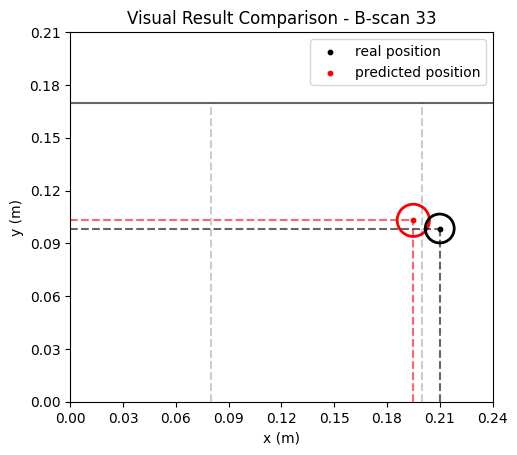

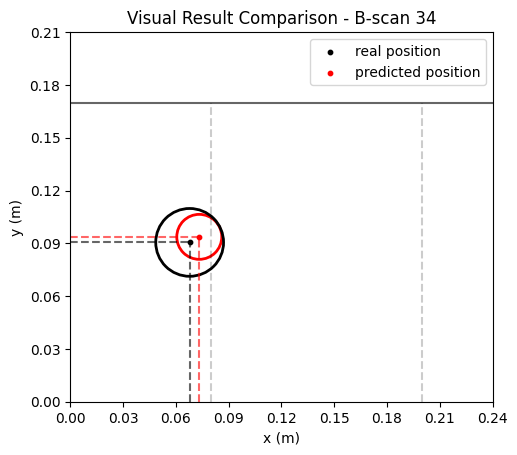

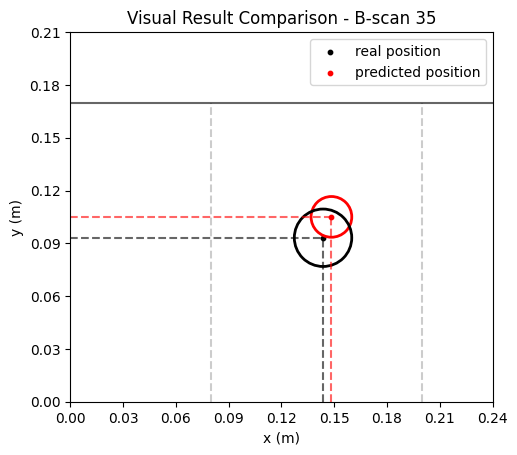

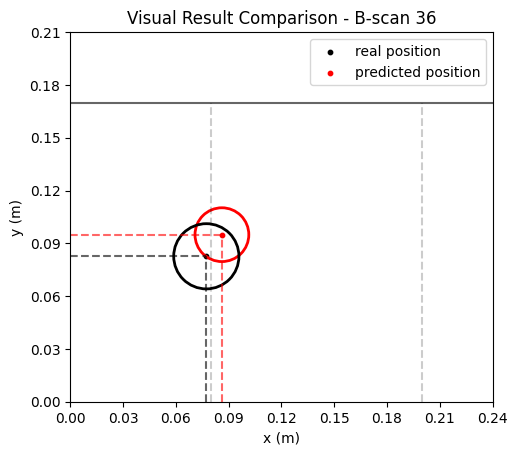

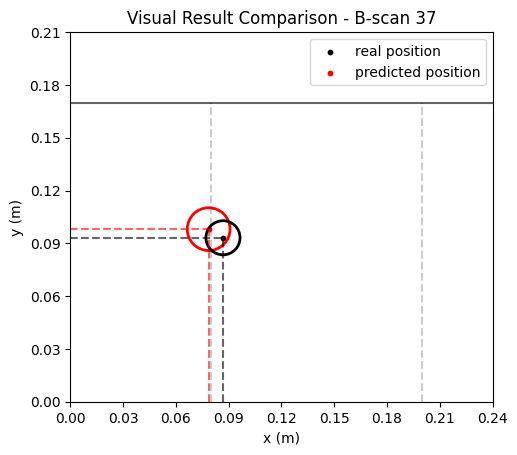

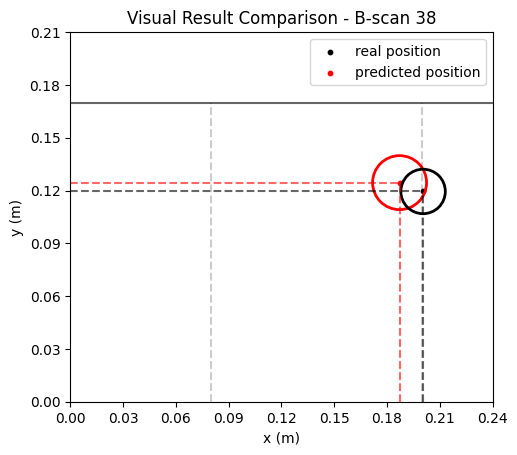

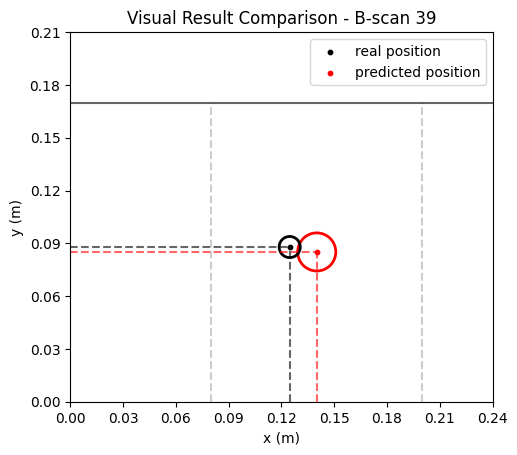

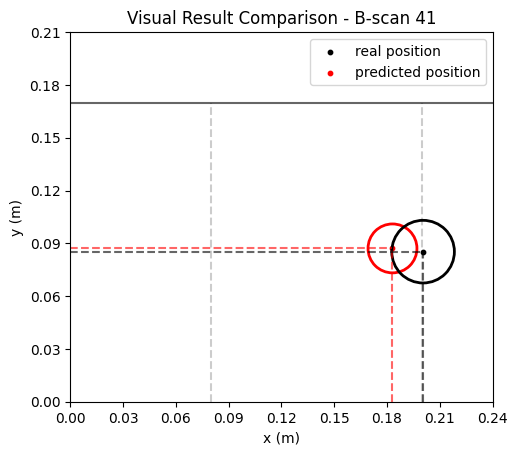

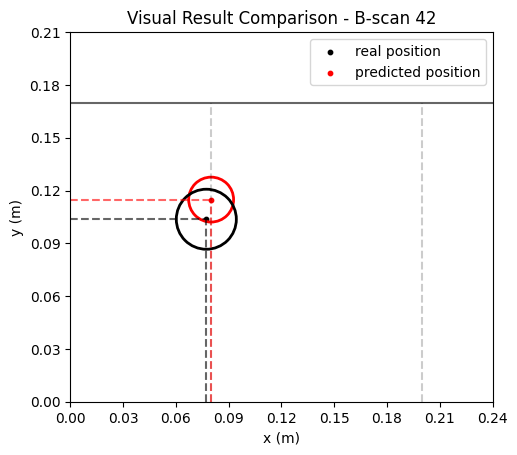

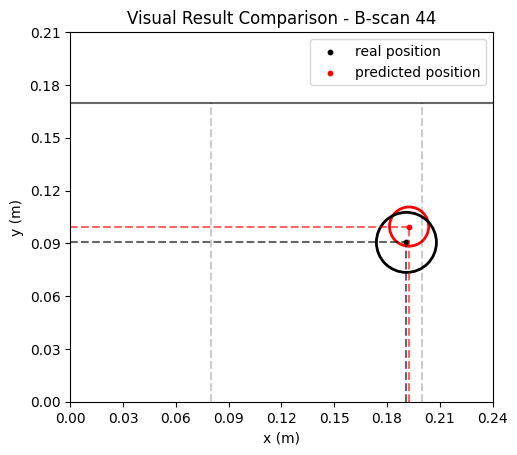

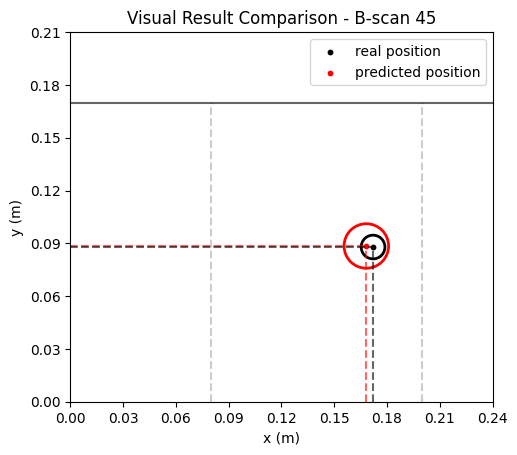

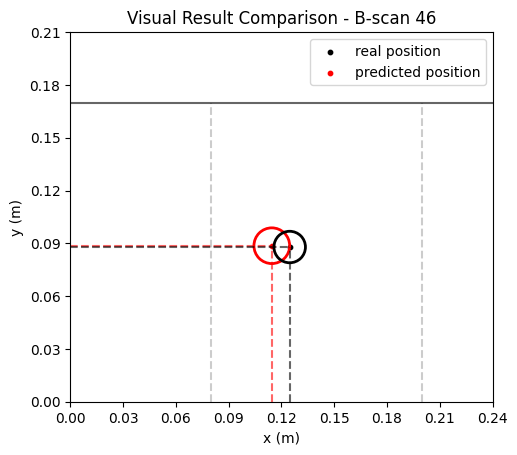

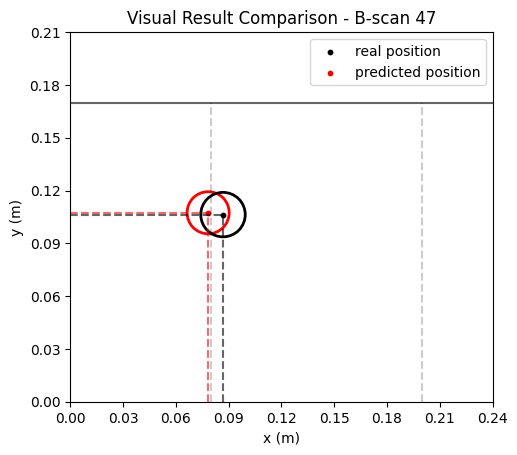

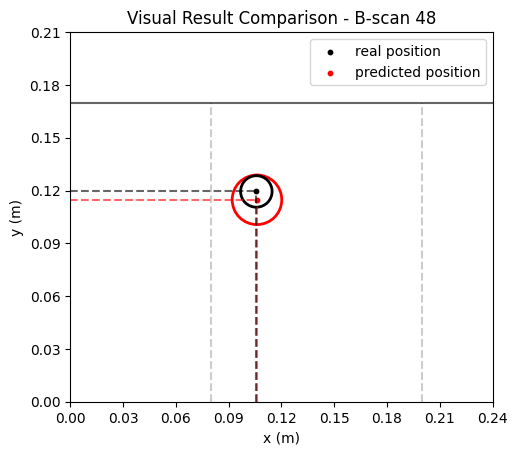

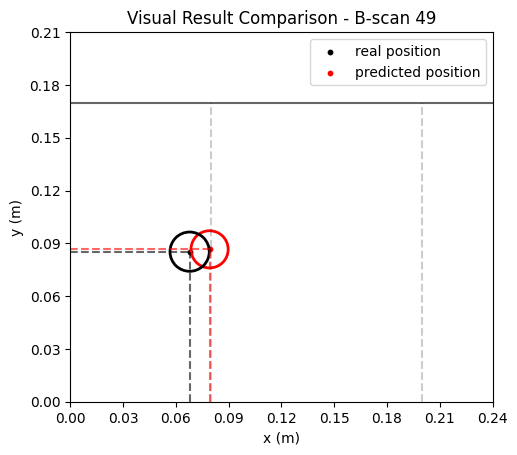

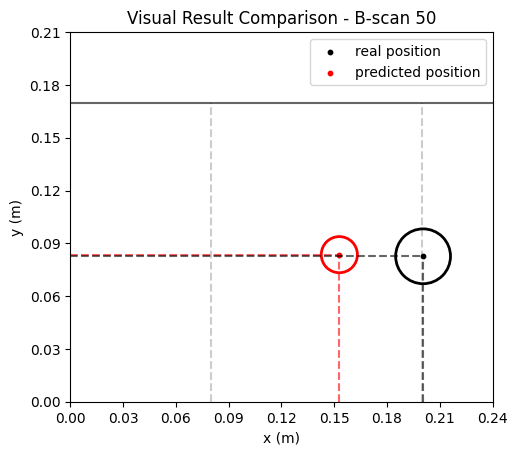

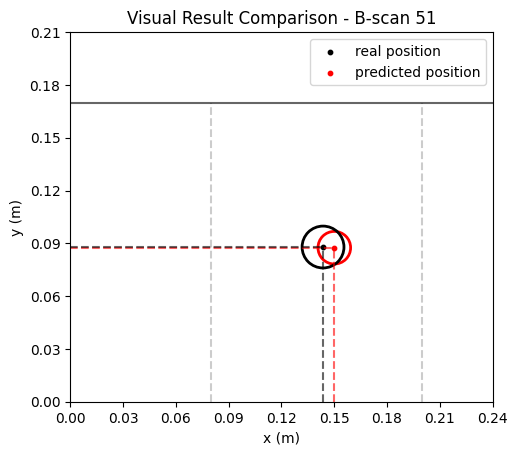

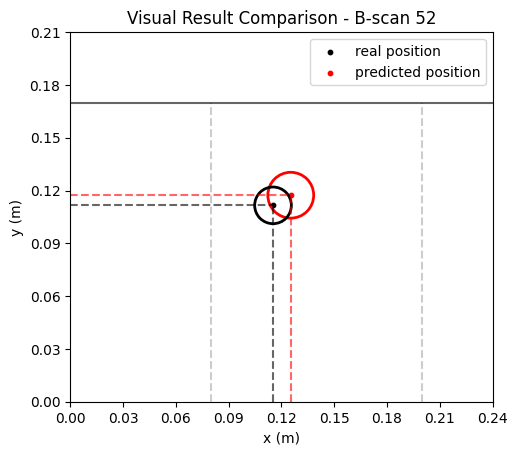

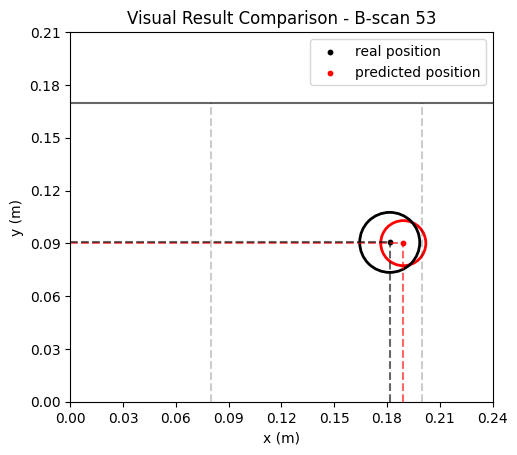

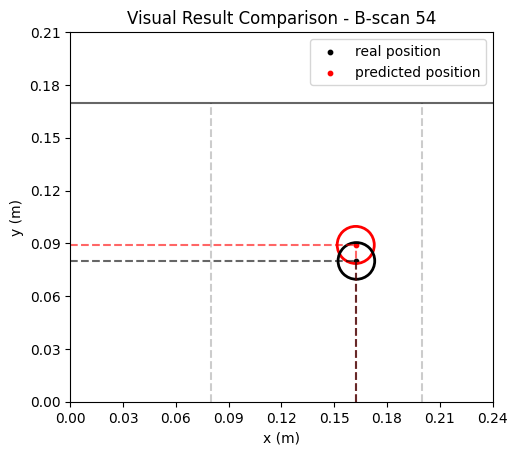

In [11]:
predictions = pd.concat((y2,y3,y4),axis=1)
real_values = df[['pos_x','pos_y','radius']][y1['presence_pred']==1].reset_index(drop=True)
# display(predictions)
# display(real_values)

pos_x_pred = predictions['pos_x_pred']
pos_y_pred = predictions['pos_y_pred']
radius_pred = predictions['radius_pred']

pos_x = real_values['pos_x']
pos_y = real_values['pos_y']
radius = real_values['radius']

idx_col = X[y1['presence_pred']==1].index

for i in range(50):
    fig, ax = plt.subplots()

    # Círculo: centro (x,y) e raio r
    circulo_real = plt.Circle((pos_x[i], pos_y[i]), radius[i], color='black', fill=False, linewidth=2)
    plt.scatter(pos_x[i], pos_y[i],color='black',s=10,label='real position')

    circulo_pred = plt.Circle((pos_x_pred[i], pos_y_pred[i]), radius_pred[i], color='red', fill=False, linewidth=2)
    plt.scatter(pos_x_pred[i], pos_y_pred[i],color='red',s=10,label='predicted position')

    ax.set_title(f'Visual Result Comparison - B-scan {idx_col[i]}')
    ax.add_patch(circulo_pred)
    ax.add_patch(circulo_real)
    ax.set_xlim(0, 0.24)
    ax.set_ylim(0, 0.21)
    ax.set_aspect('equal')
    ax.set_xticks(np.arange(0,0.241,0.03))
    ax.set_yticks(np.arange(0,0.211,0.03))
    ax.set_xlabel(r"x (m)")
    ax.set_ylabel(r"y (m)")
    ax.axvline(x=0.08,color='black',ls='--',alpha=0.2,ymax=0.17/0.21)
    ax.axvline(x=0.2,color='black',ls='--',alpha=0.2,ymax=0.17/0.21)
    ax.axhline(y=0.17,color='black',alpha=0.6)

    ax.axvline(x=pos_x_pred[i],color='red',ls='--',alpha=0.6,ymax=pos_y_pred[i]/0.21)
    ax.axvline(x=pos_x[i],color='black',ls='--',alpha=0.6,ymax=pos_y[i]/0.21)
    ax.axhline(y=pos_y_pred[i],color='red',ls='--',alpha=0.6,xmax=pos_x_pred[i]/0.24)
    ax.axhline(y=pos_y[i],color='black',ls='--',alpha=0.6,xmax=pos_x[i]/0.24)

    ax.legend()
    plt.show()

COM ESSES VALORES PREVISTOS EM MÃO, DÁ PRA IDENTIFICAR O TIPO DE SOLO??